# 02 | Exploratory data analysis

This notebook performs univariate, bivariate and segmentation analysis of cleaned Duka synthetic H1 2026 orders. It reads the SQLite table produced by `01_cleaning.ipynb`; run notebooks in order.

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
with sqlite3.connect(ROOT / "data" / "duka_sales.db") as connection:
    sales = pd.read_sql("SELECT * FROM sales", connection, parse_dates=["order_date"])
reports = ROOT / "reports"
reports.mkdir(exist_ok=True)
sales["month"] = sales["order_date"].dt.to_period("M").astype(str)
sales["day_type"] = sales["order_date"].dt.dayofweek.map(lambda day: "Weekend" if day >= 5 else "Weekday")
print(f"{len(sales):,} clean orders | {sales.order_date.min():%d %b} to {sales.order_date.max():%d %b %Y} | KES")

1,000 clean orders | 01 Jan to 30 Jun 2026 | KES


C:\Users\SEENOI HPF\AppData\Local\Temp\ipykernel_29436\1144943675.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  sales["day_type"] = sales["order_date"].dt.dayofweek.map(lambda day: "Weekend" if day >= 5 else "Weekday")


## Univariate analysis

Inspect order revenue, order counts by channel and product, and category revenue. Order revenue is right-skewed when high-value products occur; the median is shown alongside the mean.

,units_sold,unit_price,revenue
count,1000.00,1000.00,1000.00
mean,1.70,31148.70,52464.10
std,1.02,29282.63,66136.81
min,1.00,4200.00,4200.00
25%,1.00,9100.00,16700.00
50%,1.00,25400.00,30800.00
75%,2.00,35550.00,58000.00
max,5.00,124200.00,600500.00


Orders by channel:


,orders
channel,
In-store,645
Online,355


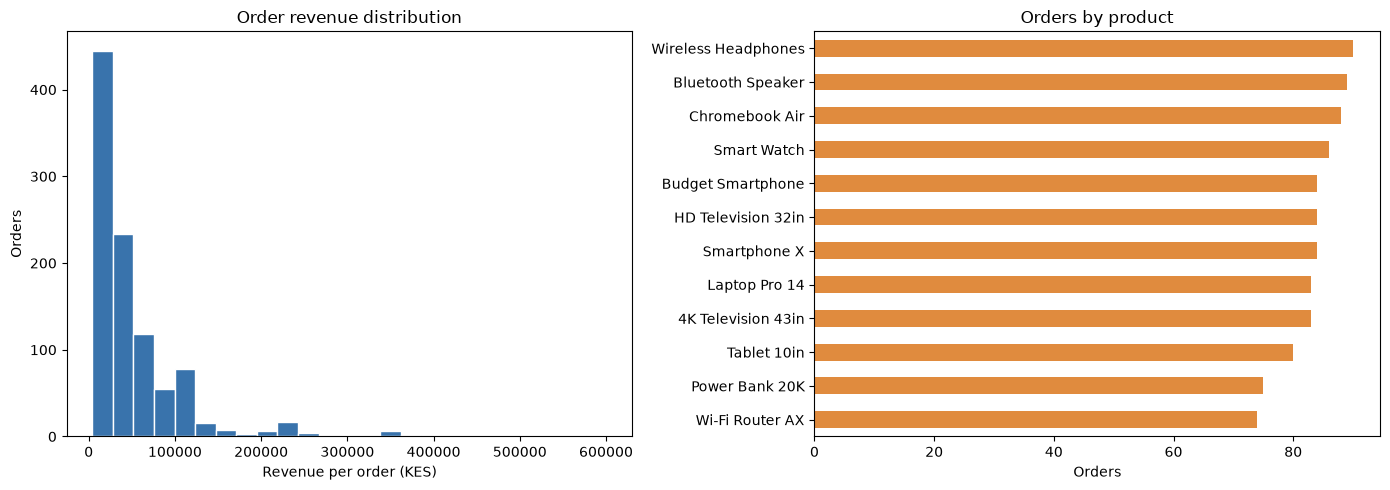

In [2]:
display(sales[["units_sold", "unit_price", "revenue"]].describe().round(2))
print("Orders by channel:")
display(sales["channel"].value_counts().rename_axis("channel").to_frame("orders"))
product_orders = sales.groupby("product").size().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(sales["revenue"], bins=25, color="#3973ac", edgecolor="white")
axes[0].set(title="Order revenue distribution", xlabel="Revenue per order (KES)", ylabel="Orders")
product_orders.plot.barh(ax=axes[1], color="#e08b3e")
axes[1].set(title="Orders by product", xlabel="Orders", ylabel="")
fig.tight_layout()
fig.savefig(reports / "univariate.png", dpi=160, bbox_inches="tight")
plt.show()

## Bivariate analysis

Compare month-by-month revenue and average order value by channel. These are descriptive associations, not causal channel effects.

,month,revenue_kes,orders
0,2026-01,8121500.0,156
1,2026-02,6703000.0,144
2,2026-03,7645500.0,161
3,2026-04,9387200.0,172
4,2026-05,9604800.0,188
5,2026-06,11002100.0,179


,channel,orders,revenue_kes,aov_kes
0,In-store,645,32966000.0,51110.08
1,Online,355,19498100.0,54924.23


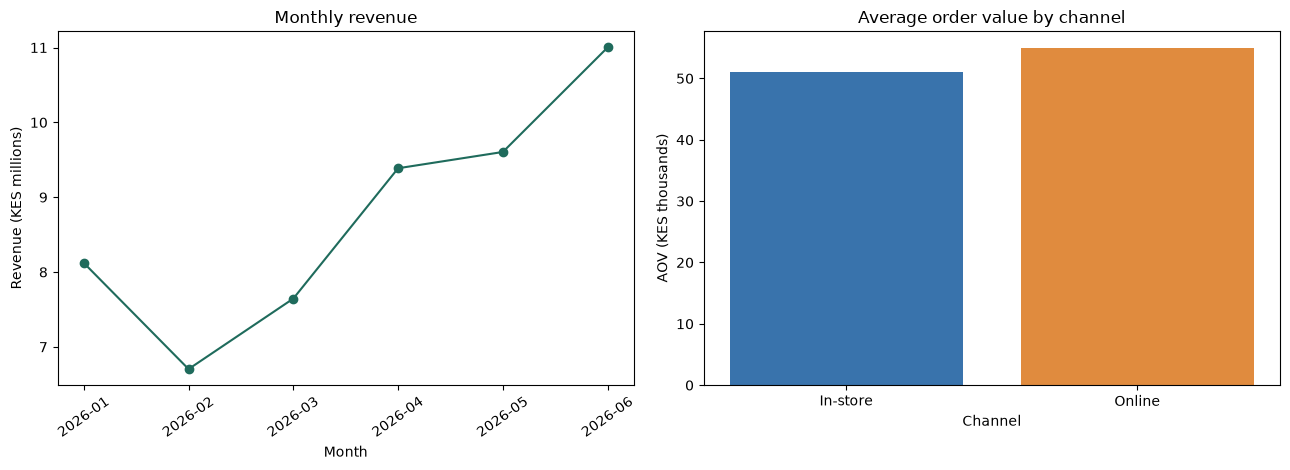

In [3]:
monthly = sales.groupby("month", as_index=False).agg(revenue_kes=("revenue", "sum"), orders=("order_id", "nunique"))
channel = sales.groupby("channel", as_index=False).agg(orders=("order_id", "nunique"), revenue_kes=("revenue", "sum"), aov_kes=("revenue", "mean"))
display(monthly)
display(channel.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(monthly["month"], monthly["revenue_kes"] / 1e6, marker="o", color="#1f6b5c")
axes[0].set(title="Monthly revenue", ylabel="Revenue (KES millions)", xlabel="Month")
axes[0].tick_params(axis="x", rotation=35)
axes[1].bar(channel["channel"], channel["aov_kes"] / 1000, color=["#3973ac", "#e08b3e"])
axes[1].set(title="Average order value by channel", ylabel="AOV (KES thousands)", xlabel="Channel")
fig.tight_layout()
fig.savefig(reports / "bivariate.png", dpi=160, bbox_inches="tight")
plt.show()

## Segmentation analysis

Rank branches by revenue and compare revenue mix across product categories. Treat these as prioritisation signals; branch size, stock and costs are not available to explain performance.

,branch,orders,revenue_kes,aov_kes
2,Mombasa,132,8180000.0,61969.70
4,Nakuru,127,6860500.0,54019.69
3,Nairobi,121,6775000.0,55991.74
1,Kisumu,120,6671800.0,55598.33
7,Westlands,118,6605900.0,55982.20
5,Nyeri,136,6558700.0,48225.74
0,Eldoret,137,5885500.0,42959.85
6,Thika,109,4926700.0,45199.08


category,Accessories,Audio,Computing,Mobile,Networking,Television,Wearables
branch,,,,,,,
Eldoret,104500.0,255100.0,2564900.0,679200.0,203300.0,1538800.0,539700.0
Kisumu,101300.0,254900.0,3109300.0,1163700.0,181900.0,1599700.0,261000.0
Mombasa,67000.0,375400.0,4782700.0,839900.0,110800.0,1371600.0,632600.0
Nairobi,53100.0,285300.0,3172100.0,1414900.0,104800.0,1502600.0,242200.0
Nakuru,121300.0,231400.0,3108800.0,1570900.0,272800.0,1185700.0,369600.0
Nyeri,86400.0,297000.0,3528700.0,1128500.0,192800.0,846200.0,479100.0
Thika,88100.0,286700.0,1778400.0,932400.0,144900.0,1383600.0,312600.0
Westlands,75600.0,245700.0,3468100.0,838300.0,221600.0,1376700.0,379900.0


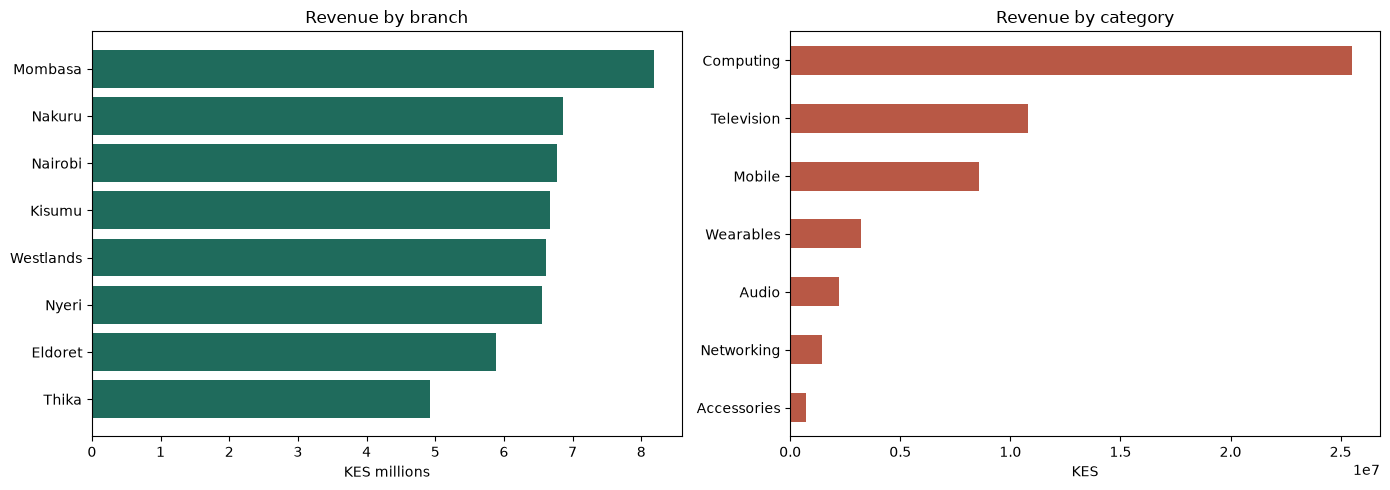

,count,mean,median,std
day_type,,,,
Weekday,698,53179.08,31450.0,65290.74
Weekend,302,50811.59,29250.0,68133.52


In [4]:
branch = sales.groupby("branch", as_index=False).agg(orders=("order_id", "nunique"), revenue_kes=("revenue", "sum"), aov_kes=("revenue", "mean")).sort_values("revenue_kes", ascending=False)
branch_category = sales.pivot_table(index="branch", columns="category", values="revenue", aggfunc="sum", fill_value=0)
display(branch.round(2))
display(branch_category)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(branch["branch"], branch["revenue_kes"] / 1e6, color="#1f6b5c")
axes[0].invert_yaxis()
axes[0].set(title="Revenue by branch", xlabel="KES millions", ylabel="")
category = sales.groupby("category")["revenue"].sum().sort_values()
category.plot.barh(ax=axes[1], color="#b85845")
axes[1].set(title="Revenue by category", xlabel="KES", ylabel="")
fig.tight_layout()
fig.savefig(reports / "segmentation.png", dpi=160, bbox_inches="tight")
plt.show()
weekend = sales.groupby("day_type")["revenue"].agg(["count", "mean", "median", "std"]).round(2)
display(weekend)